In [1]:
import os
from pathlib import Path
import pandas as pd

In [2]:
input_dir = Path("/kaggle/input/competitions/action-2026-data-mining-competition/")
csv_files = {p.name: p for p in input_dir.rglob("*.csv")}
for name, p in csv_files.items():
    print(f"- {name} -> {p}")

- sample_submission.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/sample_submission.csv
- train.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/train.csv
- test.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/test.csv


In [3]:

train_df = pd.read_csv(input_dir / "train.csv")
test_df = pd.read_csv(input_dir / "test.csv")
submission_df = pd.read_csv(input_dir / "sample_submission.csv")
print("berhasil load file")
print(train_df.info())
print(test_df.info())

berhasil load file
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23297 entries, 0 to 23296
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ID                       23297 non-null  int64 
 1   Teks                     23297 non-null  object
 2   Judul_Caption            21743 non-null  object
 3   Source                   23297 non-null  object
 4   Tanggal_Upload           23297 non-null  object
 5   Infrastruktur            23297 non-null  object
 6   Kesehatan                23297 non-null  object
 7   Administrasi_Perizinan   23297 non-null  object
 8   Lingkungan_Kebersihan    23297 non-null  object
 9   Ketertiban_Umum          23297 non-null  object
 10  Transportasi_LaluLintas  23297 non-null  object
 11  Sosial_Bantuan           23297 non-null  object
 12  Keamanan_Kriminalitas    23297 non-null  object
 13  Pendidikan               23297 non-null  object
dtypes: int64(1), object

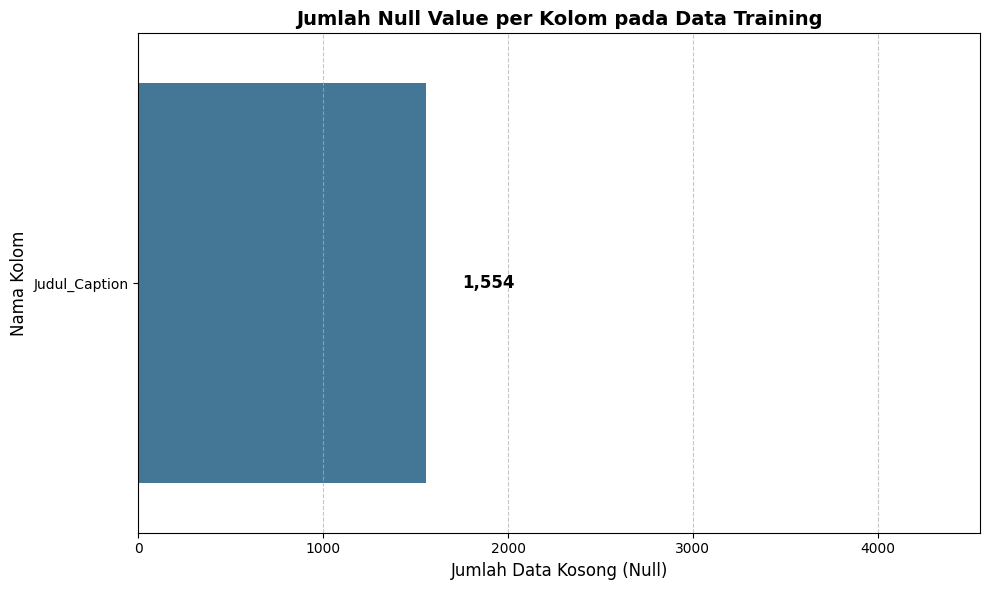

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

null_counts = train_df.isnull().sum()

null_counts = null_counts[null_counts > 0]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=null_counts.values, 
    y=null_counts.index, 
    hue=null_counts.index,      
    palette='mako', 
    legend=False                
)

plt.title('Jumlah Null Value per Kolom pada Data Training', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Data Kosong (Null)', fontsize=12)
plt.ylabel('Nama Kolom', fontsize=12)

for i, v in enumerate(null_counts.values):
    plt.text(v + 200, i, f"{v:,}", va='center', fontsize=12, fontweight='bold')

plt.xlim(0, null_counts.max() + 3000)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

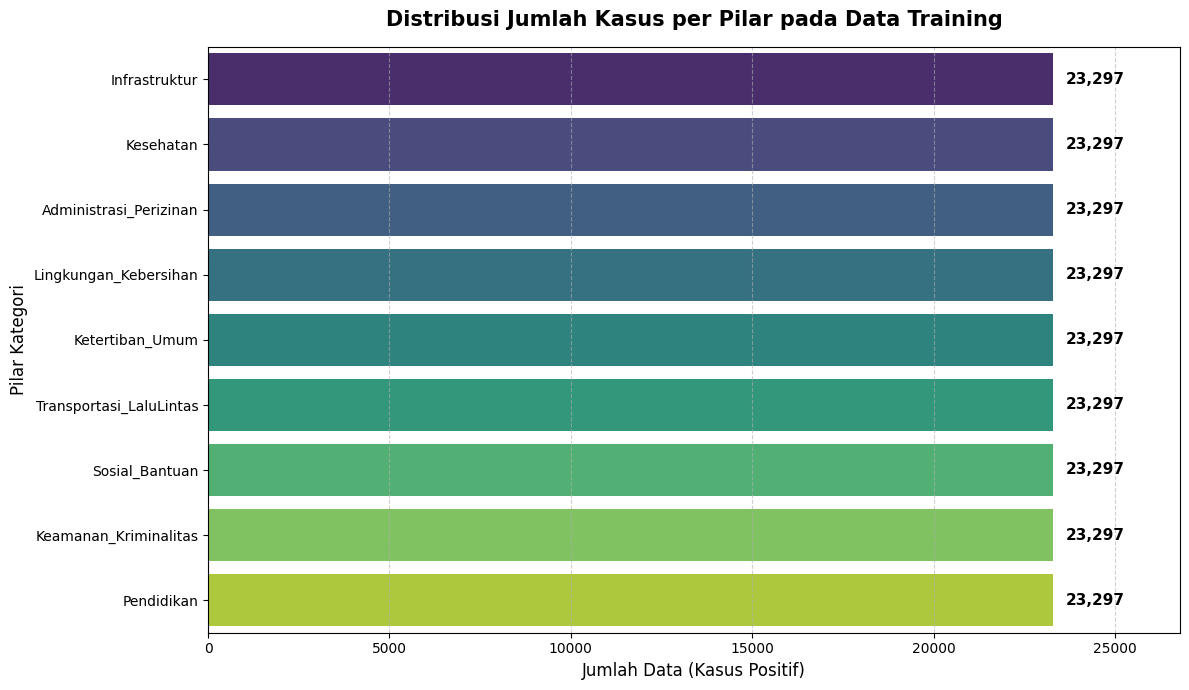

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pilar_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]

pilar_counts = {}
for col in pilar_cols:
    count = (train_df[col].astype(str).str.strip().str.lower() != '0').sum()
    pilar_counts[col] = count

counts_series = pd.Series(pilar_counts).sort_values(ascending=False)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=counts_series.values, 
    y=counts_series.index, 
    hue=counts_series.index, 
    palette='viridis', 
    legend=False
)

plt.title('Distribusi Jumlah Kasus per Pilar pada Data Training', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Jumlah Data (Kasus Positif)', fontsize=12)
plt.ylabel('Pilar Kategori', fontsize=12)

for i, v in enumerate(counts_series.values):
    plt.text(v + (counts_series.max() * 0.015), i, f"{int(v):,}", va='center', fontsize=11, fontweight='bold')

plt.xlim(0, counts_series.max() * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()